# Như — bàn giao RF và MLP

Ngày 23/11/2026. Đã xuất RF và MLP cho nhị phân và ba lớp vào `artifacts/models/group_submission`.

RF dùng EXP005 mặc định. MLP dùng pipeline EXP015 seed43 có RandomOverSampler, chốt tham số với ba nhóm subject và bốn ứng viên gốc EXP010.
Mỗi pipeline cuối đã fit trên đủ 15 người, 6.189 cửa sổ và nhận đúng 68 feature.
Điểm LOSO trong bảng là điểm thực nghiệm tham chiếu, không phải điểm test của file model refit.

Việc fit được thực thi bằng `scripts/export_nhu_models.py`; notebook đọc hồ sơ thật sau khi chạy.
Đã kiểm tra nạp cả bốn joblib trong tiến trình Python mới bằng `scripts/verify_nhu_models.py`.
Muốn xuất lại, chạy từ thư mục dự án với Python 3.12.14:
```powershell
python scripts/export_nhu_models.py --output-root artifacts/models/group_submission_new
python scripts/verify_nhu_models.py --bundle-root artifacts/models/group_submission_new
```
Lệnh dùng thư mục mới để giữ bản bàn giao cũ.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

locations=[]
for folder in [Path.cwd(), *Path.cwd().parents]:
    locations.extend([folder / "artifacts/models/group_submission",
                      folder / "wesad-stress-detection/artifacts/models/group_submission", folder])
BUNDLE=next((p for p in locations if (p/"nhu_handoff/verification.json").is_file()),None)
assert BUNDLE is not None, "Mở notebook trong dự án có artifacts/models/group_submission."
report=json.loads((BUNDLE/"nhu_handoff/verification.json").read_text(encoding="utf-8"))
assert report["status"] == "passed" and len(report["models"]) == 4
print("Ngày thực hiện: 23/11/2026")
print("Kết quả kiểm tra trong tiến trình mới:",report["status"])
display(pd.DataFrame(report["models"]))


Ngày thực hiện: 23/11/2026
Kết quả kiểm tra trong tiến trình mới: passed


model,task,n_predictions,status
rf,binary,9,passed
rf,multiclass,9,passed
mlp,binary,9,passed
mlp,multiclass,9,passed


## Điểm LOSO tham chiếu

Đây là điểm trung bình giữa 15 subject của EXP005 và EXP015 seed43. Không thay bằng điểm train/CV của model bàn giao.


In [2]:
summary=pd.read_csv(BUNDLE/"model_summary_nhu.csv")
display(summary[["model","task","experiment_id","macro_f1","macro_f1_std",
                 "balanced_accuracy","balanced_accuracy_std","n_windows_fit"]].round(4))
rows=[]
for name in ["rf","mlp"]:
    for task in ["binary","multiclass"]:
        meta=json.loads((BUNDLE/name/f"metadata_{task}.json").read_text(encoding="utf-8"))
        rows.append({"model":name,"task":task,"fit_subjects":len(meta["subjects_fit"]),
                     "fit_windows":meta["n_windows_fit"],"n_warnings":len(meta["warnings"]),
                     "chosen_params":meta["chosen_params"],"pipeline":meta["pipeline_steps"]})
display(pd.DataFrame(rows))


model,task,experiment_id,macro_f1,macro_f1_std,balanced_accuracy,balanced_accuracy_std,n_windows_fit
rf,binary,EXP-005,0.8735,0.1440,0.8865,0.1143,6189
rf,multiclass,EXP-005,0.6480,0.1297,0.6700,0.1204,6189
mlp,binary,EXP-015,0.8626,0.1233,0.8692,0.1245,6189
mlp,multiclass,EXP-015,0.6645,0.1250,0.7020,0.1171,6189


model,task,fit_subjects,fit_windows,n_warnings,chosen_params,pipeline
rf,binary,15,6189,0,{},"[imputer, model]"
rf,multiclass,15,6189,0,{},"[imputer, model]"
mlp,binary,15,6189,0,"{'model__alpha': 0.001, 'model__hidden_layer_sizes': [64, 32], 'model__learning_rate_init': 0.001}","[imputer, scaler, sampler, model]"
mlp,multiclass,15,6189,0,"{'model__alpha': 0.001, 'model__hidden_layer_sizes': [64, 32], 'model__learning_rate_init': 0.001}","[imputer, scaler, sampler, model]"


## Loss của MLP ở lượt fit cuối

Đây là train loss trên dữ liệu fit, không phải test loss. Các bước chọn tham số và điểm từng split được lưu trong `mlp/selection_binary.csv` và `mlp/selection_multiclass.csv`.


binary : 25 epoch; loss cuối: 0.000528
multiclass : 28 epoch; loss cuối: 0.000615


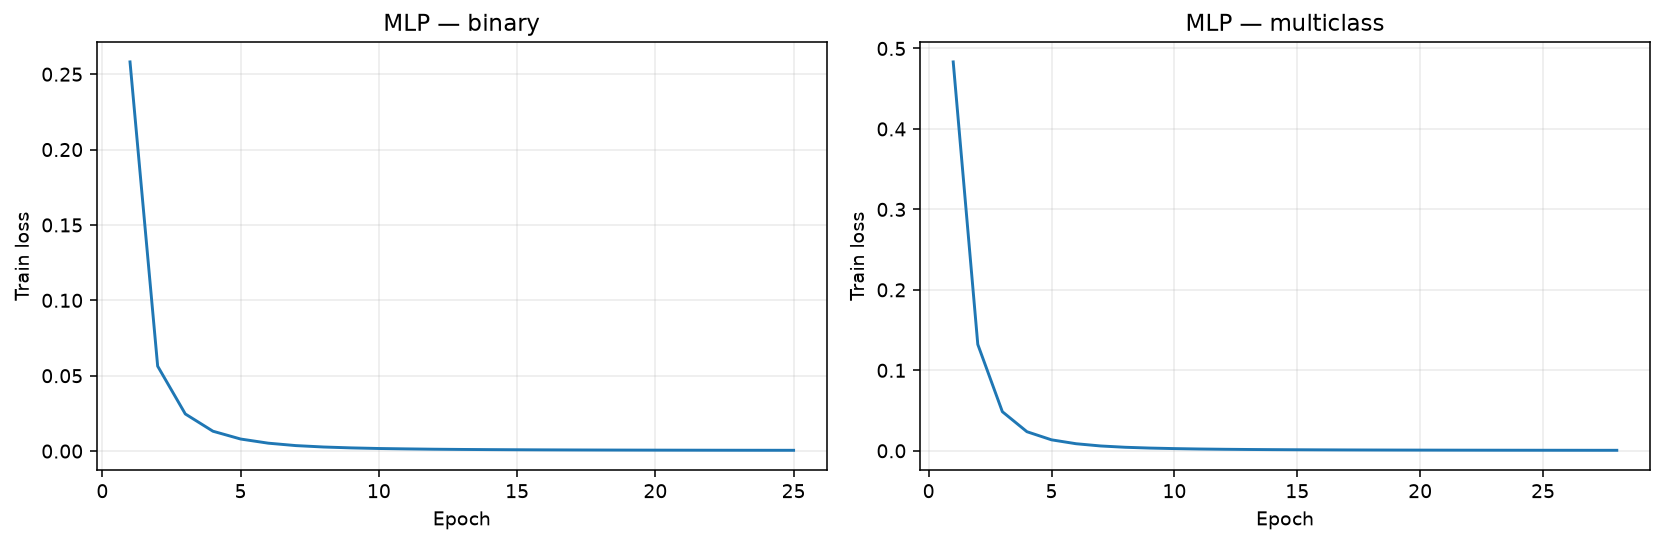

In [3]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for ax,task in zip(axes,["binary","multiclass"]):
    meta=json.loads((BUNDLE/"mlp"/f"metadata_{task}.json").read_text(encoding="utf-8"))
    curve=meta["loss_curve"]
    ax.plot(range(1,len(curve)+1),curve)
    ax.set(title=f"MLP — {task}",xlabel="Epoch",ylabel="Train loss")
    ax.grid(alpha=0.25)
    print(task,":",meta["n_iter"],"epoch; loss cuối:",round(meta["loss"],6))
fig.tight_layout()
plt.show()


## Nhận xét

Đã xuất và nạp lại đủ bốn pipeline. Dự đoán trước và sau khi lưu khớp trên toàn bộ 6.189 dòng.
Trong phiên Python mới, cả bốn pipeline dự đoán đúng định dạng và khớp CSV dự đoán mẫu; thứ tự 68 feature và tập nhãn đều đạt.
Lượt xuất này không ghi nhận cảnh báo thư viện. Không dùng dữ liệu subject/window ID hoặc nhãn làm feature.
Nhóm cần ghép danh mục với model của thành viên khác. Chưa thay cấu hình demo LR và chưa push.
